In [1]:
import pandas as pd
import os
import parser
from datetime import datetime
root_orig = "D:\\Project\\DetectRobot\\Data\\data_month6\\"

In [2]:
check_files_sameday = [f for f in sorted(os.listdir(root_orig))]


In [3]:
data = pd.read_csv(r"D:\Project\DetectRobot\Data\allFormulaBet-ver02.csv")
#data = pd.concat((pd.read_csv(os.path.join(root_orig, f),encoding='ISO-8859-1', skiprows=[1], skipfooter=1).assign(file_name = f) for f in check_files_sameday))


In [4]:
data.head()

,transid,custid,transdate,oddsid,hdp1,hdp2,odds,stake,status,winlost,...,RefCode,SettlementTime,epositiontaking,ReasonID,sort,username2,leagueid,sporttype,CustId,MatchId
0,108597780118,40713060,2020-02-19 11:30:04.323,240790245,1.00,0.0,-0.98,1000.0,DRAW,980.0,...,NaN,2020-03-11 17:51:30.677,0.0,NaN,NaN,NaN,1837,1,40713060,36768690
1,108605025803,40713060,2020-02-20 16:19:03.200,240790245,1.00,0.0,-0.92,1000.0,DRAW,920.0,...,NaN,2020-03-11 17:51:30.677,0.0,NaN,NaN,NaN,1837,1,40713060,36768690
2,108651157637,39249136,2020-02-26 12:05:02.820,241257852,2.75,0.0,0.79,5077.0,VOID,5077.0,...,NaN,NaN,0.0,NaN,NaN,NaN,5,1,39249136,34949245
3,108651278039,39269113,2020-02-26 12:24:43.497,241257852,2.50,0.0,0.85,5000.0,VOID,5000.0,...,NaN,NaN,0.0,NaN,NaN,NaN,5,1,39269113,34791813
4,108656053380,39249136,2020-02-27 07:42:20.687,242101483,1.00,0.0,-1.00,3384.0,DRAW,3384.0,...,NaN,2020-03-07 09:56:57.477,0.0,NaN,NaN,NaN,35,1,39249136,34949245


In [5]:
data['balance'].unique()

array([1.02635000e+04, 8.75137500e+03, 8.63742370e+05, ...,
       1.11768995e+07, 2.17234000e+03, 1.08268995e+07])

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1767611 entries, 0 to 1767610
Data columns (total 76 columns):
 #   Column           Dtype  
---  ------           -----  
 0   transid          int64  
 1   custid           int64  
 2   transdate        object 
 3   oddsid           int64  
 4   hdp1             float64
 5   hdp2             float64
 6   odds             float64
 7   stake            float64
 8   status           object 
 9   winlost          float64
 10  awinlost         float64
 11  mwinlost         float64
 12  playercomm       float64
 13  comm             float64
 14  acomm            float64
 15  apositiontaking  float64
 16  mpositiontaking  float64
 17  tpositiontaking  float64
 18  playerdiscount   float64
 19  discount         float64
 20  adiscount        float64
 21  livehomescore    int64  
 22  liveawayscore    int64  
 23  liveindicator    int64  
 24  betteam          object 
 25  creator          int64  
 26  refno            int64  
 27  comstatus   

In [7]:
df_minimize = data[['custid','transdate','hdp1','hdp2','odds','stake','status','winlost','liveindicator','winlostdate','betfrom','matchid','bettype','ip','Username','username2','leagueid','sporttype']]

In [8]:
df_minimize.head()

,custid,transdate,hdp1,hdp2,odds,stake,status,winlost,liveindicator,winlostdate,betfrom,matchid,bettype,ip,Username,username2,leagueid,sporttype
0,40713060,2020-02-19 11:30:04.323,1.00,0.0,-0.98,1000.0,DRAW,980.0,0,2020-03-11 00:00:00,n,34745772,1,NaN,NaN,NaN,1837,1
1,40713060,2020-02-20 16:19:03.200,1.00,0.0,-0.92,1000.0,DRAW,920.0,0,2020-03-11 00:00:00,y,34745772,1,NaN,NaN,NaN,1837,1
2,39249136,2020-02-26 12:05:02.820,2.75,0.0,0.79,5077.0,VOID,5077.0,0,2020-03-08 00:00:00,k,34791813,1,NaN,NaN,NaN,5,1
3,39269113,2020-02-26 12:24:43.497,2.50,0.0,0.85,5000.0,VOID,5000.0,0,2020-03-08 00:00:00,k,34791813,1,NaN,NaN,NaN,5,1
4,39249136,2020-02-27 07:42:20.687,1.00,0.0,-1.00,3384.0,DRAW,3384.0,0,2020-03-07 00:00:00,k,34872523,1,NaN,NaN,NaN,35,1


In [9]:
df_minimize['date'] = pd.to_datetime(df_minimize['transdate']).dt.date

ipykernel_launcher:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [10]:
df_minimize.head()

,custid,transdate,hdp1,hdp2,odds,stake,status,winlost,liveindicator,winlostdate,betfrom,matchid,bettype,ip,Username,username2,leagueid,sporttype,date
0,40713060,2020-02-19 11:30:04.323,1.00,0.0,-0.98,1000.0,DRAW,980.0,0,2020-03-11 00:00:00,n,34745772,1,NaN,NaN,NaN,1837,1,2020-02-19
1,40713060,2020-02-20 16:19:03.200,1.00,0.0,-0.92,1000.0,DRAW,920.0,0,2020-03-11 00:00:00,y,34745772,1,NaN,NaN,NaN,1837,1,2020-02-20
2,39249136,2020-02-26 12:05:02.820,2.75,0.0,0.79,5077.0,VOID,5077.0,0,2020-03-08 00:00:00,k,34791813,1,NaN,NaN,NaN,5,1,2020-02-26
3,39269113,2020-02-26 12:24:43.497,2.50,0.0,0.85,5000.0,VOID,5000.0,0,2020-03-08 00:00:00,k,34791813,1,NaN,NaN,NaN,5,1,2020-02-26
4,39249136,2020-02-27 07:42:20.687,1.00,0.0,-1.00,3384.0,DRAW,3384.0,0,2020-03-07 00:00:00,k,34872523,1,NaN,NaN,NaN,35,1,2020-02-27


In [11]:
df_groupbydate = df_minimize.groupby(['custid','matchid'])['transdate'].apply(list).to_frame()

In [12]:
df_groupbydate.head()

transdate
custid matchid                                                    
401808 34670266  [2020-03-05 16:26:48.160, 2020-03-05 17:05:33....
       34745769  [2020-03-10 16:01:48.277, 2020-03-10 16:17:57....
       34791813                          [2020-03-08 11:57:38.933]
       34850928  [2020-03-07 13:39:28.583, 2020-03-07 13:43:56....
       34850932  [2020-03-08 07:17:21.157, 2020-03-08 08:18:03....

In [13]:
df_groupbydate['Length']= df_groupbydate['transdate'].str.len()

In [14]:
df_groupbydate = df_groupbydate[df_groupbydate['Length'] > 1]

In [15]:
df_groupbydate.head()

transdate  Length
custid matchid                                                            
401808 34670266  [2020-03-05 16:26:48.160, 2020-03-05 17:05:33....       6
       34745769  [2020-03-10 16:01:48.277, 2020-03-10 16:17:57....       4
       34850928  [2020-03-07 13:39:28.583, 2020-03-07 13:43:56....       4
       34850932  [2020-03-08 07:17:21.157, 2020-03-08 08:18:03....       2
       34872523  [2020-03-07 08:04:39.333, 2020-03-07 08:25:51....       5

In [16]:
def calculate_difftime(list_data):
    list_data = sorted(list_data)
    result = [((datetime.strptime(y, '%Y-%m-%d %H:%M:%S.%f') - datetime.strptime(x, '%Y-%m-%d %H:%M:%S.%f')).seconds)/60 for x,y in zip(list_data,list_data[1:])]
    return result

In [17]:
a = ['2020-03-05 16:26:48.160',
 '2020-03-05 17:05:33.213',
 '2020-03-05 17:05:19.740',
 '2020-03-05 17:32:40.463',
 '2020-03-05 17:34:20.620',
 '2020-03-05 17:32:08.923']
a = ['2020-03-05 17:05:19.740', '2020-03-05 17:05:33.213']
#for i in range(len(a)):
    #a[i] = datetime.strptime(a[i], '%Y-%d-%m %H:%M:%S.%f')

result = [((datetime.strptime(y, '%Y-%d-%m %H:%M:%S.%f') - datetime.strptime(x, '%Y-%d-%m %H:%M:%S.%f')).seconds)/60 for x,y in zip(a,a[1:])]
print(result)

[0.21666666666666667]


In [18]:
a = ['2020-03-05 16:26:48.160',
 '2020-03-05 17:05:33.213',
 '2020-03-05 17:05:19.740',
 '2020-03-05 17:32:40.463',
 '2020-03-05 17:34:20.620',
 '2020-03-05 17:32:08.923']
a = sorted(a)
print(a)

['2020-03-05 16:26:48.160', '2020-03-05 17:05:19.740', '2020-03-05 17:05:33.213', '2020-03-05 17:32:08.923', '2020-03-05 17:32:40.463', '2020-03-05 17:34:20.620']


In [19]:
df_groupbydate_2 = df_groupbydate.reset_index()

In [20]:
df_groupbydate_2.head()

,custid,matchid,transdate,Length
0,401808,34670266,"[2020-03-05 16:26:48.160, 2020-03-05 17:05:33....",6
1,401808,34745769,"[2020-03-10 16:01:48.277, 2020-03-10 16:17:57....",4
2,401808,34850928,"[2020-03-07 13:39:28.583, 2020-03-07 13:43:56....",4
3,401808,34850932,"[2020-03-08 07:17:21.157, 2020-03-08 08:18:03....",2
4,401808,34872523,"[2020-03-07 08:04:39.333, 2020-03-07 08:25:51....",5


In [32]:
df_groupbydate_2[df_groupbydate_2['custid'] == 45662233]['transdate']

331825    [2020-10-15 18:46:31.743, 2020-10-16 18:19:45....
Name: transdate, dtype: object

In [22]:
df_groupbydate['diff_time'] = df_groupbydate['transdate'].apply(calculate_difftime)

In [23]:
df_groupbydate.sample(10)

,,transdate,Length,diff_time
custid,matchid,,,
43107076,36003478,"[2020-05-17 03:52:29.513, 2020-05-17 03:53:29....",2,[1.0]
36729404,37398335,"[2020-07-26 11:22:17.167, 2020-07-26 12:42:15....",2,[79.95]
38486039,35517095,"[2020-04-11 04:39:22.637, 2020-04-11 04:41:22....",5,"[8.316666666666666, 1.9833333333333334, 25.616..."
38707051,35730405,"[2020-04-24 15:02:26.067, 2020-04-24 15:04:13....",4,"[1.7833333333333334, 17.983333333333334, 0.15]"
42276922,37289251,"[2020-07-15 06:28:37.593, 2020-07-15 06:30:24....",3,"[22.083333333333332, 1.7833333333333334]"
45067086,38437246,"[2020-09-16 08:34:05.197, 2020-09-16 08:34:36....",3,"[0.5, 0.9]"
31893357,37548566,"[2020-07-27 11:24:29.320, 2020-07-27 11:42:03....",2,[17.55]
38381225,36968660,"[2020-07-01 04:38:51.257, 2020-07-01 04:39:19....",20,"[0.4666666666666667, 0.06666666666666667, 0.18..."
43227756,39222414,"[2020-10-20 15:34:57.817, 2020-10-20 15:38:40....",2,[3.7]


In [47]:
def checkbigger(list_data):
    count = 0
    for i in list_data:
        if i <= 15:
            count += 1
    return count

In [48]:
df_groupbydate['isBigger'] = df_groupbydate['diff_time'].apply(checkbigger)

In [49]:
df_groupbydate.head()

transdate  Length  \
custid matchid                                                               
401808 34670266  [2020-03-05 16:26:48.160, 2020-03-05 17:05:33....       6   
       34745769  [2020-03-10 16:01:48.277, 2020-03-10 16:17:57....       4   
       34850928  [2020-03-07 13:39:28.583, 2020-03-07 13:43:56....       4   
       34850932  [2020-03-08 07:17:21.157, 2020-03-08 08:18:03....       2   
       34872523  [2020-03-07 08:04:39.333, 2020-03-07 08:25:51....       5   

                                                         diff_time  isBigger  
custid matchid                                                                
401808 34670266  [38.516666666666666, 0.21666666666666667, 26.5...         3  
       34745769                                [16.15, 6.55, 0.25]         2  
       34850928     [4.45, 0.18333333333333332, 7.066666666666666]         3  
       34850932                                             [60.7]         0  
       34872523  [21.183333333333334, 0.13333333333333333, 41.6...         2

In [189]:
df_groupbydate_2[df_groupbydate_2['custid'] == 42703161] 

,custid,matchid,transdate,Length
182241,42703161,36968756,"[2020-07-02 03:30:34.700, 2020-07-02 03:38:33....",2
182242,42703161,36968766,"[2020-07-02 07:54:19.367, 2020-07-02 07:56:07....",3
182243,42703161,36968767,"[2020-07-02 05:56:36.627, 2020-07-02 07:50:42....",2
182244,42703161,36971299,"[2020-07-02 10:52:43.007, 2020-07-02 10:52:50....",4
182245,42703161,36971300,"[2020-07-02 13:09:35.667, 2020-07-02 13:09:41....",3
182246,42703161,36971309,"[2020-07-02 13:09:57.987, 2020-07-02 13:10:02....",3
182247,42703161,36971310,"[2020-07-02 14:42:11.477, 2020-07-02 13:51:15....",6
182248,42703161,36983220,"[2020-07-07 13:14:56.623, 2020-07-07 13:50:11....",3
182249,42703161,36985244,"[2020-07-03 05:24:34.223, 2020-07-03 01:16:32....",2
182250,42703161,36985260,"[2020-07-03 08:05:24.207, 2020-07-03 08:05:32....",3


In [179]:
list_difftime = df_groupbydate['diff_time'].to_list()

In [180]:
flatten_matrix = [val for sublist in list_difftime for val in sublist]
df = pd.DataFrame(flatten_matrix,columns=['mse'])
df.head()

,mse
0,38.516667
1,0.216667
2,26.583333
3,0.516667
4,1.666667


In [183]:
df[df['mse'] > 1200]

,mse,label
2207,1286.083333,5
6729,1428.316667,5
8018,1293.666667,5
8335,1353.650000,5
9351,1241.533333,5
...,...,...
1011234,1385.550000,5
1012171,1255.266667,5
1012176,1349.166667,5
1014025,1395.283333,5


In [181]:
from sklearn.cluster import KMeans
import numpy as np

#kmeans = KMeans(n_clusters=2, random_state=0).fit(flatten_matrix)
kmeans = KMeans(n_clusters=8)
df['label'] = kmeans.fit_predict(df[['mse']])

In [128]:
df['label'].unique()

array([0, 6, 2, 4, 7, 3, 1, 5])

In [153]:
print(kmeans.cluster_centers_.ravel())

[   2.6769986  1365.98042611  534.83754224   29.97797402  177.45347881
   70.56665317  791.57121348  333.16025795 1426.31557057 1160.23283753]


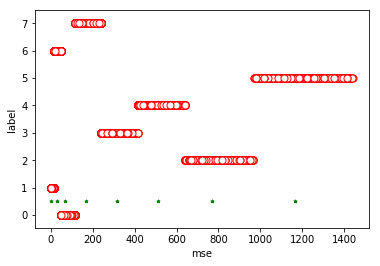

In [182]:
import matplotlib.pyplot as plt
#plt.figure(figsize=(50,60))
ax = df[df['label']==0].plot.scatter(x='mse', y='label', s=50, color='white', edgecolor='black')

#df[df['label']==1].plot.scatter(x='mse', y='label', s=500, color='white', ax=ax, edgecolor='red')
#plt.scatter(kmeans.cluster_centers_.ravel(), [0.5]*len(kmeans.cluster_centers_))
#plt.show()
u_labels = df['label'].unique()
for i in u_labels:
    df[df['label']==i].plot.scatter(x='mse', y='label', s=50, color='white', ax=ax,edgecolor='red')
plt.scatter(kmeans.cluster_centers_.ravel(), [0.5]*len(kmeans.cluster_centers_), s=10, color='green', marker='*')